# NOAA GHCN Weather Data Pipeline for Africa
### A Practical Guide to Station Discovery, Data Ingestion, and Climate Analysis

---

### Overview
NOAA's Global Historical Climatology Network (GHCN) provides decades of global surface weather data. However, working with it directly is challenging because data is split across raw S3 Parquet buckets, integer tenths scaling (e.g., $254$ for $25.4$ mm), missing value sentinels (`-9999`), and fixed-width text inventories.

`masharikiweather` provides a clean Python wrapper (`ghcn_apiwrapper.py`) that handles all of this automatically:
- **Discovers stations** by region, country name, or bounding box coordinates.
- **Inspects sensor lifecycles** independently (so an ended thermometer doesn't crash an active rain query).
- **Downloads and cleans data** concurrently with unit normalization (tenths $\rightarrow$ mm and °C).
- **Safely extracts time series** without `KeyError` crashes.
- **Visualizes data completeness** and missing days using heatmaps.
- **Aligns ground stations** with ERA5 gridded reanalysis.

| Key Feature | Function / Method | What it does |
| :--- | :--- | :--- |
| **Global Station Discovery** | `get_stations(...)` / `get_african_stations(...)` | Finds stations globally (Netherlands, Europe, etc.) or Africa by preset. |
| **Sensor Activeness** | `GHCNDaily.get_stations_variable_activeness(...)` | Checks independent start/end years for each sensor. |
| **Daily Ingestion** | `query_ghcn_daily(...)` | One-line multi-station, multi-variable clean download. |
| **Safe Extraction** | `get_station_series(df, station, variable)` | Extracts a station's series safely without `KeyError`. |
| **Hourly Ingestion** | `query_ghcn_hourly(...)` | Sub-daily telemetry from airport AWOS/ASOS stations. |
| **Grid Alignment** | `pipeline.align(target_meta, ...)` | Pairs ground stations to ERA5 0.25° grid centroids. |


## 1. Environment Setup & Imports

We start by loading our libraries and importing the pipeline tools from `masharikiweather`.

In [19]:
import os
try:
    import folium
except ImportError:
    folium = None

try:
    import seaborn as sns
except ImportError:
    sns = None

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Import MasharikiWeather GHCN tools
import masharikiweather as mw
from masharikiweather import (
    GHCN,
    GHCNDaily,
    GHCNHourly,
    query_ghcn_daily,
    query_ghcn_hourly,
    check_ghcn_availability,
    check_station_coverage,
    check_variable_activeness,
    get_station_series,
    get_variable_lifecycle,
    get_stations,
    get_african_stations,
    GLOBAL_REGIONS,
    CONTINENT_REGIONS,
)

print(f"MasharikiWeather version: {mw.__version__}")


MasharikiWeather version: 0.2.0


## 2. Station Discovery Methods

Before downloading data, we need to know which stations exist and where they are located.  
`GHCNDaily.get_african_stations(...)` provides three ways to discover stations:
1. **By Region Preset**: Built-in African geographic presets (`'kenya'`, `'east_africa'`, `'west_africa'`, `'southern_africa'`, `'central_africa'`, `'north_africa'`, `'africa'`).
2. **By Country Name**: Any country or list of countries (e.g. `'Nigeria'`, `['Kenya', 'Tanzania']`).
3. **By Geographic Bounding Box**: Coordinate limits `(min_lat, min_lon, max_lat, max_lon)` (e.g. Mali / Sahel: `(10.0, -12.25, 25.0, 4.25)`).

Let us test all three methods:

In [20]:
# --- Method 1: Discover Active Stations in Kenya (2020 to Date) ---
ke_stations = GHCNDaily.get_african_stations(
    region="kenya",
    active_only=True,
    min_year=2020,
    include_inventory=True
)
print(f"Method 1 (Region 'kenya'): Found {len(ke_stations)} active stations.")
display(ke_stations[['ID', 'NAME', 'LAT', 'LON', 'ELEV', 'status', 'elements_available']].head(6))

# --- Method 2: Discover Stations in Nigeria and Ghana ---
west_stations = GHCNDaily.get_african_stations(
    countries=["Nigeria", "Ghana"],
    include_inventory=True
)
print(f"\nMethod 2 (Countries 'Nigeria' & 'Ghana'): Found {len(west_stations)} stations.")
display(west_stations[['ID', 'NAME', 'country_name', 'status', 'elements_available']].head(6))

# --- Method 3: Discover Stations in a Custom Bounding Box (Mali: 10°N to 25°N, 12.25°W to 4.25°E) ---
bbox_stations = GHCNDaily.get_african_stations(
    bounds=(10.0, -12.25, 25.0, 4.25), # (min_lat, min_lon, max_lat, max_lon)
    include_inventory=True
)
print(f"\nMethod 3 (Mali Bounding Box): Found {len(bbox_stations)} stations.")
display(bbox_stations[['ID', 'NAME', 'LAT', 'LON', 'status']].head(6))

Method 1 (Region 'kenya'): Found 10 active stations.


,ID,NAME,LAT,LON,ELEV,status,elements_available
0,KEM00063686,ELDORET INTL,0.404,35.239,2115.6,Active,"PRCP, TAVG, TMAX, TMIN"
1,KE000063723,GARISSA,-0.467,39.633,147.0,Active,"PRCP, TAVG, TMAX, TMIN"
2,KE000063740,JOMO KENYATTA INTL,-1.317,36.917,1624.0,Active,"PRCP, SNWD, TAVG, TMAX, TMIN"
3,KE000063661,KITALE,1.016,35.000,1875.0,Active,"PRCP, SNWD, TAVG, TMAX, TMIN"
4,KE000063612,LODWAR,3.117,35.617,515.0,Active,"PRCP, TAVG, TMAX, TMIN"
5,KEM00063799,MALINDI,-3.229,40.102,25.0,Active,"PRCP, TAVG, TMAX, TMIN"



Method 2 (Countries 'Nigeria' & 'Ghana'): Found 28 stations.


,ID,NAME,country_name,status,elements_available
0,GHM00065437,KETE-KRACHI,Ghana,Active,"PRCP, TAVG, TMAX, TMIN"
1,NIM00065123,MINNA,Nigeria,Active,"PRCP, TAVG, TMAX, TMIN"
2,GHM00065457,AKIM ODA,Ghana,Active,"PRCP, TAVG, TMAX, TMIN"
3,GHM00065460,AKUSE,Ghana,Active,"PRCP, TAVG, TMAX, TMIN"
4,GHM00065465,AXIM,Ghana,Active,"PRCP, TAVG, TMAX, TMIN"
5,GHM00065416,BOLE,Ghana,Active,"PRCP, TAVG, TMAX, TMIN"



Method 3 (Mali Bounding Box): Found 56 stations.


,ID,NAME,LAT,LON,status
0,UV000065516,BOROMO,11.750,-2.933,Active
1,NGM00061053,DOSSO,13.033,3.300,Active
2,UVM00065518,PO,11.150,-1.150,Active
3,MLM00061265,AMBODEDJO,14.513,-4.080,Active
4,UVM00065510,BOBO DIOULASSO,11.160,-4.331,Active
5,MLM00061296,BOUGOUNI,11.417,-7.500,Active


### Interactive Station Map
To inspect station coverage visually, we can plot them on an interactive `folium` map.  
- **Green pins** = Active stations reporting in recent years.
- **Crimson pins** = Historical stations that ceased operations.

In [21]:
# Plot Kenya's active stations on an interactive map
if folium is not None and not ke_stations.empty:
    center_lat = ke_stations['LAT'].astype(float).mean()
    center_lon = ke_stations['LON'].astype(float).mean()
    station_map = folium.Map(location=[center_lat, center_lon], zoom_start=6, tiles='OpenStreetMap')

    for _, row in ke_stations.iterrows():
        status = str(row.get('status', 'Unknown'))
        color = 'forestgreen' if 'Active' in status else 'crimson'
        popup_text = (
            f"<b>Station:</b> {row['ID']}<br>"
            f"<b>Name:</b> {row['NAME']}<br>"
            f"<b>Status:</b> {status}<br>"
            f"<b>Elements:</b> {row.get('elements_available', 'N/A')}<br>"
            f"<b>Elevation:</b> {row.get('ELEV', 'N/A')} m"
        )
        folium.CircleMarker(
            location=[float(row['LAT']), float(row['LON'])],
            radius=7,
            popup=folium.Popup(popup_text, max_width=300),
            tooltip=f"{row['ID']} - {row['NAME']}",
            color=color,
            fill=True,
            fillOpacity=0.75
        ).add_to(station_map)

    display(station_map)
elif not ke_stations.empty:
    print(f"Identified {len(ke_stations)} active stations in Kenya. (Install folium to view interactive map)")


## 3. Sensor Activeness & Independent Lifecycles

A common pitfall in African climatology is assuming all sensors at a station start and end at the same time. In reality, a station's manual rain gauge might be active today, but its automatic thermometer broke in 2015.  

`GHCNDaily.get_stations_variable_activeness(...)` checks the lifecycle of each sensor independently so we know exactly what is available before requesting data.

In [22]:
# Check independent sensor lifecycles for sample stations
sample_ids = ke_stations['ID'].head(5).tolist()
sensor_lifecycles = GHCNDaily.get_stations_variable_activeness(stations=sample_ids)

display(sensor_lifecycles[['station', 'name', 'rain_status', 'tmax_status', 'wind_status', 'active_variables', 'ended_variables']])

,station,name,rain_status,tmax_status,wind_status,active_variables,ended_variables
0,KE000063612,LODWAR,Active (thru 2025),Active (thru 2025),Not Recorded,"tmax, tmin, rain, tavg",None
1,KE000063661,KITALE,Active (thru 2025),Active (thru 2025),Not Recorded,"tmax, tmin, rain, tavg",snow_depth (1983)
2,KE000063723,GARISSA,Active (thru 2025),Active (thru 2025),Not Recorded,"tmax, tmin, rain, tavg",None
3,KE000063740,JOMO KENYATTA INTL,Active (thru 2025),Active (thru 2025),Not Recorded,"tmax, tmin, rain, tavg",snow_depth (2014)
4,KEM00063686,ELDORET INTL,Active (thru 2024),Active (thru 2026),Not Recorded,"tmax, tmin, rain, tavg",None


## 4. Fetching Daily Weather Observations

`query_ghcn_daily(...)` downloads, quality-checks, and scales observations in a single call:
- Raw integer tenths are divided by 10 (tenths of mm $\rightarrow$ mm, tenths of °C $\rightarrow$ °C).
- Sentinel values (`-9999`) and impossible readings are removed.
- Diurnal Temperature Range ($DTR = T_{\max} - T_{\min}$) is computed automatically if requested.
- Formats the result as a Wide matrix (`Date` $\times$ `Stations/Variables`).

In [23]:
START_DATE = "2024-01-01"
END_DATE = "2024-12-31"

print(f"Fetching daily observations across Kenya for {START_DATE[:4]}...")
daily_wide_df = query_ghcn_daily(
    region="kenya",
    variables=["tp", "t2m_max", "t2m_min", "dtr"],
    start_date=START_DATE,
    end_date=END_DATE,
    format="wide",
    active_only=True,
    min_year=2020
)

print(f"Shape: {daily_wide_df.shape} (Days, Station-Variable combinations)")
display(daily_wide_df.head())

Fetching daily observations across Kenya for 2024...
[GHCN Sensor Notice] Station 'KE000063619' (MOYALE):
  • 't2m_max': Decommissioned (ended 2023 < query start 2024)
  • 'dtr': Decommissioned (temp ended 2023 < query start 2024)
[GHCN Sensor Notice] Station 'KE000063624' (MANDERA):
  • 't2m_max': Decommissioned (ended 2011 < query start 2024)
  • 'dtr': Decommissioned (temp ended 2011 < query start 2024)
Shape: (356, 35) (Days, Station-Variable combinations)


station    KE000063612                       KE000063619     KE000063624      \
variable           dtr t2m_max t2m_min    tp     t2m_min  tp     t2m_min  tp   
time                                                                           
2024-01-01         NaN     NaN    23.0  13.0        18.9 NaN        23.0 NaN   
2024-01-02         NaN     NaN    24.6   0.0        18.8 NaN        22.6 NaN   
2024-01-03        11.9    37.3    25.4   NaN        18.2 NaN        22.0 NaN   
2024-01-04         NaN     NaN     NaN   NaN        18.3 NaN        20.5 NaN   
2024-01-05         NaN     NaN    23.8   NaN        17.9 NaN        20.0 NaN   

station    KE000063661          ... KEM00063686     KEM00063741          \
variable           dtr t2m_max  ...     t2m_min  tp         dtr t2m_max   
time                            ...                                       
2024-01-01         NaN     NaN  ...         NaN NaN         NaN     NaN   
2024-01-02         NaN     NaN  ...        13.9 NaN         NaN     NaN   
2024-01-03         NaN     NaN  ...         NaN NaN         NaN     NaN   
2024-01-04         NaN     NaN  ...        11.9 NaN         9.2    25.2   
2024-01-05         NaN     NaN  ...        10.8 NaN         NaN    25.4   

station                 KEM00063799                      
variable   t2m_min   tp         dtr t2m_max t2m_min  tp  
time                                                     
2024-01-01    17.4  NaN         NaN     NaN     NaN NaN  
2024-01-02    17.5  NaN         NaN     NaN     NaN NaN  
2024-01-03    17.2  NaN         NaN     NaN    26.6 NaN  
2024-01-04    16.0  NaN         NaN    32.7     NaN NaN  
2024-01-05     NaN  0.0         6.7    32.3    25.6 NaN  

[5 rows x 35 columns]

## 5. Missing Data & Network Coverage Heatmap

Weather telemetry often contains gaps due to sensor maintenance or transmission delays.  
A missing data heatmap gives us an instant view of data completeness across all stations over the year:  
- **Purple** = Valid recorded observation.
- **Yellow** = Missing observation (`NaN`).

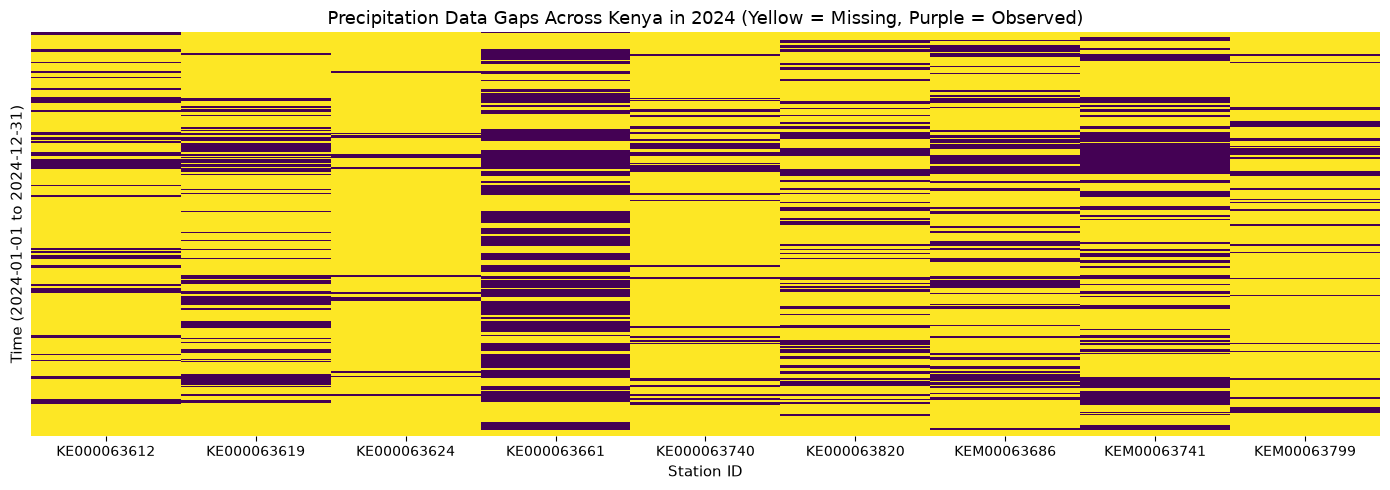

In [24]:
# Extract precipitation ('tp') across all stations
if not daily_wide_df.empty and isinstance(daily_wide_df.columns, pd.MultiIndex):
    prcp_matrix = daily_wide_df.xs('tp', axis=1, level=1)

    plt.figure(figsize=(14, 5))
    if sns is not None:
        sns.heatmap(prcp_matrix.isna(), cbar=False, cmap='viridis', yticklabels=False)
    else:
        plt.imshow(prcp_matrix.isna().values, aspect='auto', cmap='viridis')
        plt.xticks(range(len(prcp_matrix.columns)), prcp_matrix.columns, rotation=90)
    plt.title(f"Precipitation Data Gaps Across Kenya in {START_DATE[:4]} (Yellow = Missing, Purple = Observed)", fontsize=13)
    plt.xlabel("Station ID", fontsize=11)
    plt.ylabel(f"Time ({START_DATE} to {END_DATE})", fontsize=11)
    plt.tight_layout()
    plt.show()


## 6. Safe Time Series Extraction & Station Analytics

When analyzing a specific station, using `df[station][variable]` will crash with a `KeyError` if that station didn't record that variable.  

`get_station_series(df, station, variable)` extracts a 1D `pd.Series` safely without crashing, returning an empty Series if missing.  

Let us examine **Eldoret International Airport (`KEM00063686`)** across 3 synchronized panels:
1. **Precipitation (mm)**: Daily rainfall bars and seasonal total.
2. **Temperature Extremes (°C)**: Maximum and Minimum temperatures.
3. **Diurnal Temperature Range (DTR in °C)**: Day-night temperature difference ($T_{\max} - T_{\min}$).

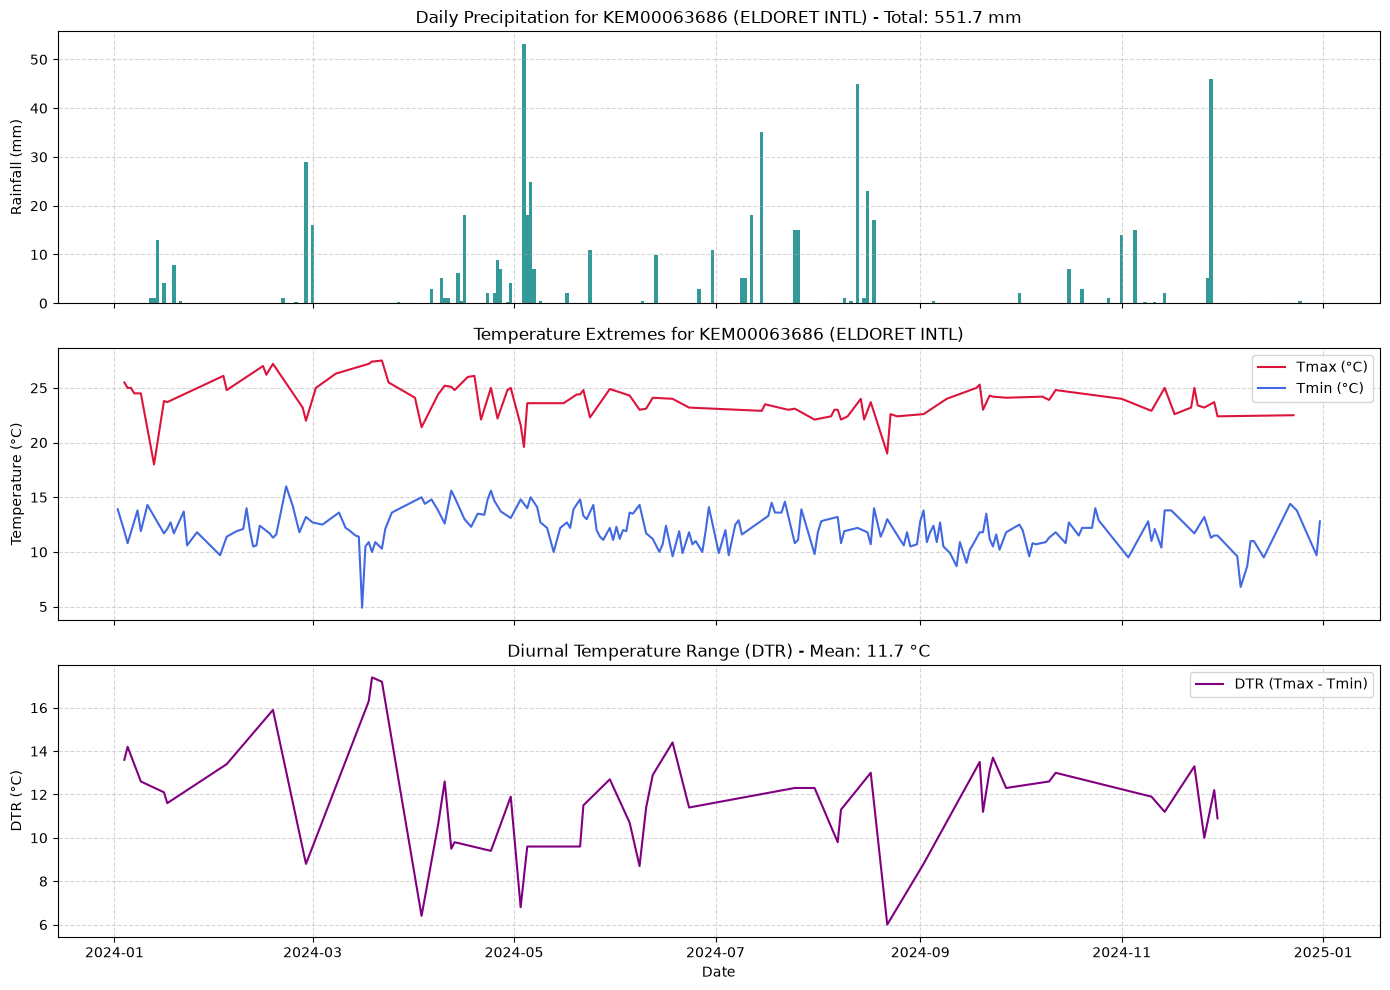

In [25]:
TARGET_STATION = "KEM00063686" # Eldoret Intl
st_name = ke_stations.loc[ke_stations['ID'] == TARGET_STATION, 'NAME'].values[0] if TARGET_STATION in ke_stations['ID'].values else TARGET_STATION

# Safely extract series (guaranteed no KeyError)
s_rain = get_station_series(daily_wide_df, station=TARGET_STATION, variable="tp")
s_tmax = get_station_series(daily_wide_df, station=TARGET_STATION, variable="t2m_max")
s_tmin = get_station_series(daily_wide_df, station=TARGET_STATION, variable="t2m_min")
s_dtr  = get_station_series(daily_wide_df, station=TARGET_STATION, variable="dtr")

fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

# 1. Daily Rainfall
if not s_rain.empty and s_rain.dropna().count() > 0:
    clean_rain = s_rain.dropna()
    axes[0].bar(clean_rain.index, clean_rain.values, color='teal', width=1.0, alpha=0.8)
    axes[0].set_title(f"Daily Precipitation for {TARGET_STATION} ({st_name}) - Total: {clean_rain.sum():.1f} mm", fontsize=12)
    axes[0].set_ylabel("Rainfall (mm)")
    axes[0].grid(True, linestyle="--", alpha=0.5)

# 2. Temperature Extremes
if not s_tmax.empty and s_tmax.dropna().count() > 0:
    axes[1].plot(s_tmax.index, s_tmax.values, color='crimson', label='Tmax (°C)', lw=1.5)
    if not s_tmin.empty and s_tmin.dropna().count() > 0:
        axes[1].plot(s_tmin.index, s_tmin.values, color='royalblue', label='Tmin (°C)', lw=1.5)
    axes[1].set_title(f"Temperature Extremes for {TARGET_STATION} ({st_name})", fontsize=12)
    axes[1].set_ylabel("Temperature (°C)")
    axes[1].legend(loc="upper right")
    axes[1].grid(True, linestyle="--", alpha=0.5)

# 3. Diurnal Temperature Range (DTR)
if not s_dtr.empty and s_dtr.dropna().count() > 0:
    axes[2].plot(s_dtr.index, s_dtr.values, color='purple', label='DTR (Tmax - Tmin)', lw=1.5)
    axes[2].set_title(f"Diurnal Temperature Range (DTR) - Mean: {s_dtr.dropna().mean():.1f} °C", fontsize=12)
    axes[2].set_ylabel("DTR (°C)")
    axes[2].set_xlabel("Date")
    axes[2].legend(loc="upper right")
    axes[2].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

## 7. Long Format for Machine Learning

For training machine learning models or Graph Neural Networks (GNNs), a long tabular format is preferred over a sparse matrix.  
Specifying `format='long'` yields a standardized table with columns: `['time', 'lat', 'lon', 'station', 'observation', 'variable']`.

In [26]:
pipeline = GHCN(resolution="daily", region="kenya", active_only=True, min_year=2020)
daily_long_df = pipeline(
    variables=["tp", "t2m_max", "t2m_min"],
    start_date=START_DATE,
    end_date=END_DATE,
    format="long"
)

print(f"Long Table Shape: {daily_long_df.shape}")
display(daily_long_df.head())

print("\nSummary statistics across variables:")
display(daily_long_df.groupby("variable")["observation"].describe())

Long Table Shape: (3988, 8)


,time,lat,lon,elev,station,observation,variable,lat_lon
0,2024-01-01,3.117,35.617,515.0,KE000063612,13.0,tp,3.117_35.617
1,2024-01-02,3.117,35.617,515.0,KE000063612,0.0,tp,3.117_35.617
2,2024-01-16,3.117,35.617,515.0,KE000063612,20.1,tp,3.117_35.617
3,2024-01-17,3.117,35.617,515.0,KE000063612,0.0,tp,3.117_35.617
4,2024-01-27,3.117,35.617,515.0,KE000063612,0.0,tp,3.117_35.617



Summary statistics across variables:


,count,mean,std,min,25%,50%,75%,max
variable,,,,,,,,
t2m_max,806.0,27.921216,4.186715,18.0,24.8,27.2,31.1,38.9
t2m_min,2335.0,20.019700,5.452124,4.9,14.8,21.5,25.0,29.3
tp,847.0,5.901535,12.343429,0.0,0.0,0.5,6.1,114.0


## 8. Cross-Country African Exploration

The pipeline works seamlessly across all African countries. Let us query an active Southern African synoptic station: **Maun, Botswana (`BC000068032`)** to inspect its semi-arid climate telemetry.

In [27]:
BW_STATION = "BC000068032" # Maun, Botswana

print(f"Fetching climate data for Maun, Botswana ({BW_STATION}) for 2024...")
bw_df = query_ghcn_daily(
    stations=[BW_STATION],
    variables=["rain", "tmax", "tmin", "dtr"],
    start_date="2024-01-01",
    end_date="2024-12-31",
    format="wide"
)

display(bw_df.head())

bw_rain = get_station_series(bw_df, station=BW_STATION, variable="rain")
bw_tmax = get_station_series(bw_df, station=BW_STATION, variable="tmax")
bw_dtr  = get_station_series(bw_df, station=BW_STATION, variable="dtr")

print(f"\nClimate Analytics for Maun, Botswana (2024):")
print(f"  • Total Rainfall:       {bw_rain.dropna().sum():.1f} mm across {bw_rain.dropna().count()} rain days")
print(f"  • Mean Max Temperature: {bw_tmax.dropna().mean():.1f} °C")
print(f"  • Mean Diurnal Range:   {bw_dtr.dropna().mean():.1f} °C")

Fetching climate data for Maun, Botswana (BC000068032) for 2024...


station    BC000068032                 
variable           dtr rain  tmax  tmin
time                                   
2024-01-01         NaN  4.3   NaN  20.6
2024-01-02         NaN  NaN   NaN  21.0
2024-01-03         NaN  3.8   NaN   NaN
2024-01-04         NaN  0.0   NaN  22.0
2024-01-05         NaN  NaN  34.4   NaN


Climate Analytics for Maun, Botswana (2024):
  • Total Rainfall:       118.5 mm across 71 rain days
  • Mean Max Temperature: 33.2 °C
  • Mean Diurnal Range:   16.7 °C


## 9. Sub-Daily Telemetry (GHCN-Hourly)

For convective storm tracking and diurnal wind studies, airport stations report sub-daily hourly telemetry (temperature `t2m`, dew point `d2m`, relative humidity `rh`, wind speed `wind_speed`).

NOAA NCEI hosts hourly data on their object store with two primary access methods:
1. **`by_year` (Default/Auto)**: Annual slices (`.parquet` or `.psv`) for specific query years (~500 KB/station-year).
2. **`by_station`**: Full Period-of-Record (POR) archives (`.psv`) from [`hourly/access/by-station/`](https://www.ncei.noaa.gov/oa/global-historical-climatology-network/index.html#hourly/access/by-station/).

The wrapper automatically resolves station identifiers (e.g. airport ICAO codes like `HKJK` and `HKNW`, or WMO IDs) to their official NOAA GHCNh IDs (`KEI0000HKJK`, `KEI0000HKNW`), applies physical QC, and caches data locally.

In [28]:
# Query airport hourly observations (JKIA Nairobi and Wilson)
hourly_df = query_ghcn_hourly(
    stations=["HKJK", "HKNW"],
    variables=["t2m", "d2m", "rh", "wind_speed"],
    start_date="2024-07-01",
    end_date="2024-07-05",
    format="long",
    access_method="auto"  # Options: 'auto', 'by_year', or 'by_station'
)

if not hourly_df.empty:
    print(f"Retrieved {len(hourly_df)} hourly observations:")
    display(hourly_df.head(6))
    
    # Inspect summary statistics for JKIA and Wilson
    print("\nMean temperature and humidity by station:")
    display(hourly_df.groupby(["station", "variable"])["observation"].mean().unstack())
else:
    print("Hourly observations not present in local cache for test window.")


Retrieved 1079 hourly observations:


,time,lat,lon,elev,station,observation,variable,lat_lon,ghcn_id
0,2024-07-01 00:00:00,-1.3192,36.9278,1623.7,HKJK,13.1,t2m,-1.319_36.928,KEI0000HKJK
1,2024-07-01 00:30:00,-1.3192,36.9278,1623.7,HKJK,13.0,t2m,-1.319_36.928,KEI0000HKJK
2,2024-07-01 01:00:00,-1.3192,36.9278,1623.7,HKJK,13.0,t2m,-1.319_36.928,KEI0000HKJK
3,2024-07-01 02:00:00,-1.3192,36.9278,1623.7,HKJK,13.0,t2m,-1.319_36.928,KEI0000HKJK
4,2024-07-01 02:30:00,-1.3192,36.9278,1623.7,HKJK,13.0,t2m,-1.319_36.928,KEI0000HKJK
5,2024-07-01 03:00:00,-1.3192,36.9278,1623.7,HKJK,12.5,t2m,-1.319_36.928,KEI0000HKJK



Mean temperature and humidity by station:


variable,d2m,rh,t2m,wind_speed
station,,,,
HKJK,11.829412,NaN,18.982843,2.442157
HKNW,11.176271,62.542373,19.027966,1.621239


## 10. Global Weather Querying: Anywhere in the World (e.g. Netherlands & Europe)

While African climate telemetry is the core focus and first-class priority of `MasharikiWeather`, the wrapper is completely general and usable by researchers anywhere across the globe.

You can query:
1. **Any country worldwide** by name (e.g. `'Netherlands'`, `'Germany'`, `'Japan'`, `'United States'`) or NOAA/ISO 2-letter country code (`'NL'`, `'GM'`, `'US'`).
2. **Any continent preset**: `'europe'`, `'north_america'`, `'south_america'`, `'asia'`, `'oceania'`, alongside African presets (`'kenya'`, `'east_africa'`, `'west_africa'`, `'southern_africa'`, `'africa'`).
3. **Both Daily and Hourly datasets** with automatic airport ICAO code resolution (e.g. Amsterdam Schiphol `EHAM` $\rightarrow$ `NLMU0029295`).

Let us demonstrate discovering stations in the Netherlands and querying observations from the historic Royal Netherlands Meteorological Institute (KNMI) observatory at **De Bilt (`NLM00006260`)** and **Amsterdam Airport Schiphol (`EHAM`)**.

In [29]:
# --- 1. Global Station Discovery: Netherlands & Europe ---
nl_daily_stations = get_stations(countries="Netherlands", resolution="daily", include_inventory=False)
nl_hourly_stations = get_stations(countries="Netherlands", resolution="hourly")
eu_stations = get_stations(region="europe", resolution="daily", include_inventory=False)

print(f"Worldwide Station Discovery:")
print(f"  • Netherlands GHCN-Daily Stations:   {len(nl_daily_stations)}")
print(f"  • Netherlands GHCN-Hourly Stations:  {len(nl_hourly_stations)}")
print(f"  • European Continent Daily Stations: {len(eu_stations)}")

print("\nSample Netherlands Hourly Stations:")
display(nl_hourly_stations[["ID", "NAME", "LAT", "LON", "country_code"]].head(5))

# --- 2. Querying Daily Observations in the Netherlands (De Bilt - NLM00006260) ---
NL_STATION = "NLM00006260" # De Bilt, Netherlands
print(f"\nFetching daily weather observations for De Bilt, Netherlands ({NL_STATION})...")
df_nl_daily = query_ghcn_daily(
    stations=[NL_STATION],
    variables=["t2m_max", "t2m_min", "tp"],
    start_date="2024-01-01",
    end_date="2024-01-14",
    format="wide"
)
display(df_nl_daily.head(7))

# --- 3. Querying Hourly Observations in the Netherlands (Amsterdam Schiphol - EHAM) ---
print("\nFetching hourly observations for Amsterdam Airport Schiphol (ICAO: EHAM)...")
df_nl_hourly = query_ghcn_hourly(
    stations=["EHAM"],
    variables=["t2m", "ws10m", "dew_point"],
    start_date="2024-01-01",
    end_date="2024-01-03",
    format="wide"
)
display(df_nl_hourly.head(6))


Worldwide Station Discovery:
  • Netherlands GHCN-Daily Stations:   386
  • Netherlands GHCN-Hourly Stations:  95
  • European Continent Daily Stations: 5544

Sample Netherlands Hourly Stations:


,ID,NAME,LAT,LON,country_code
0,NLA00062000,YPENBURG(NAFB),52.033,4.350,NL
1,NLA00062451,TERSCHELLINGERBANK,53.483,4.767,NL
2,NLA00062500,TERSCHELLING(LGT-H),53.367,5.217,NL
3,NLA00062721,RAMSPOL,52.617,5.850,NL
4,NLA00063001,NOORHINDER,51.650,2.567,NL



Fetching daily weather observations for De Bilt, Netherlands (NLM00006260)...


station    NLM00006260              
variable       t2m_max t2m_min    tp
time                                
2024-01-01         9.1     6.4  10.3
2024-01-02        12.9     6.8  24.0
2024-01-03        11.0     8.0  12.4
2024-01-04         9.2     6.0  10.6
2024-01-05         9.0     5.1   5.5
2024-01-06         5.1     0.7   0.0
2024-01-07         1.4    -2.0   0.0


Fetching hourly observations for Amsterdam Airport Schiphol (ICAO: EHAM)...


station                  EHAM           
variable            dew_point  t2m ws10m
time                                    
2024-01-01 00:00:00       6.0  7.5  12.0
2024-01-01 00:25:00       6.0  7.0  10.8
2024-01-01 00:55:00       6.0  7.0  10.3
2024-01-01 01:00:00       6.0  7.2  11.0
2024-01-01 01:25:00       6.0  8.0   9.3
2024-01-01 01:55:00       6.0  8.0  10.3

## 11. Spatial Alignment with ERA5 Reanalysis Grid

To evaluate or bias-correct climate models, `pipeline.align(...)` calculates great-circle Haversine distances to match each ground station to its closest 0.25° ERA5 reanalysis grid point.

In [30]:
# Construct 0.25° ERA5 coordinate centroids over Kenya
grid_lats = np.arange(-4.75, 5.51, 0.25)
grid_lons = np.arange(33.75, 42.01, 0.25)
mesh_lat, mesh_lon = np.meshgrid(grid_lats, grid_lons)

era5_meta = pd.DataFrame({
    "station_id": [f"ERA5_{lat:.2f}_{lon:.2f}" for lat, lon in zip(mesh_lat.ravel(), mesh_lon.ravel())],
    "latitude": mesh_lat.ravel(),
    "longitude": mesh_lon.ravel(),
})

# Find closest grid centroid for each GHCN station
era5_alignment = pipeline.align(target_meta=era5_meta, target_name="era5")
display(era5_alignment.head(6))

,ghcn_station,lat,lon,era5_nearest_label,distance_km
0,KE000063612,3.117,35.617,ERA5_3.00_35.50,18.385544
1,KE000063619,3.533,39.033,ERA5_3.50_39.00,5.184478
2,KE000063624,3.933,41.867,ERA5_4.00_41.75,14.964911
3,KE000063661,1.016,35.000,ERA5_1.00_35.00,1.779119
4,KE000063723,-0.467,39.633,ERA5_-0.50_39.75,13.516943
5,KE000063740,-1.317,36.917,ERA5_-1.25_37.00,11.859106


## 12. Exporting Clean Data

Finally, export the cleaned datasets and alignment tables to disk in fast, portable Parquet and CSV formats.

In [31]:
output_dir = os.path.abspath("processed_ghcn_output")
os.makedirs(output_dir, exist_ok=True)

wide_path = os.path.join(output_dir, f"ghcn_kenya_wide_{START_DATE[:4]}.parquet")
long_path = os.path.join(output_dir, f"ghcn_kenya_long_{START_DATE[:4]}.parquet")
align_path = os.path.join(output_dir, "ghcn_kenya_era5_alignment.csv")

daily_wide_df.to_parquet(wide_path)
daily_long_df.to_parquet(long_path, index=False)
era5_alignment.to_csv(align_path, index=False)

print("✓ Successfully exported:")
print(f"  • Wide observations: {wide_path}")
print(f"  • Long format:       {long_path}")
print(f"  • Grid alignment:    {align_path}")

✓ Successfully exported:
  • Wide observations: c:\Users\SAMMY\Documents\dsail\antigravity\esfm\MasharikiWeather\processed_ghcn_output\ghcn_kenya_wide_2024.parquet
  • Long format:       c:\Users\SAMMY\Documents\dsail\antigravity\esfm\MasharikiWeather\processed_ghcn_output\ghcn_kenya_long_2024.parquet
  • Grid alignment:    c:\Users\SAMMY\Documents\dsail\antigravity\esfm\MasharikiWeather\processed_ghcn_output\ghcn_kenya_era5_alignment.csv
